In [1]:
## packages for cloud data intake: 
import s3fs
import fsspec

## packages for analysis
import pandas as pd
import xarray as xr
%config InlineBackend.figure_format = 'retina'
import seaborn as sb
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy import feature as cf
import cmocean
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import os
!pip install colormaps   #always need to install packages
import colormaps as cmaps
from dask import delayed
import rioxarray as rxr
import glob
from scipy.stats import pearsonr
from tqdm import tqdm

### USEFUL FUNCTIONS

In [10]:
## Load this helper function

def open_s3_xarray_ukesm(bucket, group, scenario, variable_name, partial_filename, anon=False):
    fs = s3fs.S3FileSystem(anon=anon)
    keys = fs.glob(f"{bucket}/{group}/{scenario}/{variable_name}_{partial_filename}*.nc")
    urls = [f"simplecache::s3://{k}" for k in keys][:2]
    print(f"{bucket}/{group}/{scenario}/{variable_name}_{partial_filename}*.nc")
    ds = xr.open_mfdataset(
        urls,
        engine="h5netcdf",
        combine="by_coords",
        parallel=True,
        backend_kwargs={
            "storage_options": {
                "s3": {"anon": anon},
                "simplecache": {"cache_storage": "/tmp/s3cache"},
            }
        },
    )
    lon_names = ['longitude', 'lon']
    lon_name = [ln for ln in lon_names if ln in ds][0]
    
    lat_names = ['latitude', 'lat']
    lat_name = [lt for lt in lat_names if lt in ds][0]
    print(lat_name)
    
    # ds = ds.assign_coords({lon_name:((ds[lon_name] + 180) % 360 - 180)}).sortby(lon_name)
    ds = ds.assign_coords({lon_name: ((ds[lon_name] + 180) % 360 - 180)}).sortby(lon_name)
    if lon_name != "lon":
        ds = ds.rename({lon_name: "lon", lat_name:"lat"})
    
    return ds#.load()


## Load this helper function

def open_s3_xarray_waccm(bucket, group, scenario, variable_name, partial_filename, anon=False,anon1=True):
    fs = s3fs.S3FileSystem(anon=anon)
    keys = fs.glob(f"{bucket}/{group}/{scenario}{variable_name}{partial_filename}.*.nc")
    urls = [f"simplecache::s3://{k}" for k in keys]
    urls.sort()
    print(urls)
    print(f"{bucket}/{group}/{scenario}{variable_name}{partial_filename}*.nc")
    ds = [xr.open_mfdataset(
        [url],
        engine="h5netcdf",
        combine="by_coords",
        parallel=True,
        backend_kwargs={
            "storage_options": {
                "s3": {"anon": anon1},
                "simplecache": {"cache_storage": "/tmp/s3cache"},
            }
        },
    ) for url in urls]

    # print(ds)
    # ds[-1] = ds[-1].sel(time=slice("2080","2084"))
    
    ds = xr.concat(ds,dim='time')
    lon_names = ['longitude', 'lon']
    lon_name = [ln for ln in lon_names if ln in ds][0]
    
    lat_names = ['latitude', 'lat']
    lat_name = [lt for lt in lat_names if lt in ds][0]
    print(lat_name)
    
    # ds = ds.assign_coords({lon_name:((ds[lon_name] + 180) % 360 - 180)}).sortby(lon_name)
    ds = ds.assign_coords({lon_name: ((ds[lon_name] + 180) % 360 - 180)}).sortby(lon_name)
    if lon_name != "lon":
        ds = ds.rename({lon_name: "lon", lat_name:"lat"})
    
    return ds


def cart_plot(axes,ix, ncols=3,nrows=3, rlon=-150,llon=-60,tlat=42,blat=15):
    axes.add_feature(cf.BORDERS,linewidth=0.2) #add features (boarders )
    axes.add_feature(cf.COASTLINE,linewidth=1,color='gray') #coastlines 
    gl=axes.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.5, color='gray', alpha=0.01, linestyle='--') #create the map type with grids 
    axes.set_extent([llon,rlon,blat,tlat]) #set the extent of the map
    if ix%ncols ==0:
        
        gl.top_labels = False; gl.left_labels = True #set which axis labels should show 
        gl.right_labels=False; gl.xlines = False; gl.bottom_labels=False

    elif ix>=(ncols*nrows)-ncols:
        gl.top_labels = False; gl.left_labels = False #set which axis labels should show 
        gl.right_labels=False; gl.xlines = False; gl.bottom_labels=True

    else:
        gl.top_labels = False; gl.left_labels = False #set which axis labels should show 
        gl.right_labels=False; gl.xlines = False; gl.bottom_labels=False
    if ix == (ncols*nrows)-ncols:
        gl.top_labels = False; gl.left_labels = True #set which axis labels should show 
        gl.right_labels=False; gl.xlines = False; gl.bottom_labels=True
    axes.xformatter = LONGITUDE_FORMATTER;  axes.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'color':'black','size':12} #change font style for x-axis 
    gl.ylabel_style = {'color':'black','size':12}#change font style for y-axis  

convert = lambda x: chr(ord('`')+(x+1)) if x<26 else chr(ord('`')+((x)//25))+chr(ord('`')+(x+1)%26)

### LOAD DATA

In [4]:
temp_var = "tas"
variables = ["psl", temp_var]
catalog = pd.read_csv("https://cmip6-pds.s3.amazonaws.com/pangeo-cmip6.csv")


def open_hist_ensemble_mean(source):
    rows = catalog.query(
        "activity_id == 'CMIP' and source_id == @source and "
        "experiment_id == 'historical' and table_id == 'Amon' and "
        "grid_label == 'gn' and variable_id in @variables"
    ).drop_duplicates("zstore").copy()

    # Keep the latest catalog version of each member-variable pair.
    rows["release"] = rows["zstore"].str.extract(r"/v(\d{8})(?:/|$)", expand=False)
    if "version" in rows:
        version = rows["version"].astype(str).str.extract(r"(\d{8})", expand=False)
        rows["release"] = rows["release"].fillna(version)

    keys = ["member_id", "variable_id"]
    duplicates = rows.duplicated(keys, keep=False)
    if rows.loc[duplicates, "release"].isna().any():
        raise ValueError(f"{source}: could not resolve duplicate catalog versions.")

    rows = rows.sort_values("release").drop_duplicates(keys, keep="last")
    stores = rows.pivot(index="member_id", columns="variable_id", values="zstore")
    stores = stores.reindex(columns=variables).dropna()
    if stores.empty:
        raise ValueError(f"{source}: no members with both {variables}.")

    # Use the same members for pressure and temperature within this model.
    members = []
    for member, paths in stores.iterrows():
        fields = []
        for var in variables:
            da = xr.open_zarr(
                paths[var], consolidated=True, chunks={}, storage_options={"anon": True}
            )[var]

            da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
            da = da.sortby("lon").sortby("lat").sel(
                time=slice("1981", "2014"), lon=slice(-25, 25), lat=slice(0, 35)
            )
            da = da.sel(time=da.time.dt.month.isin([6, 7, 8, 9]))
            fields.append(da)

        members.append(xr.merge(fields, join="exact").expand_dims(member=[member]))

    ensemble = xr.concat(members, dim="member", join="exact")

    # Verify one value per JJAS month in each of the 34 years.
    expected = [100 * y + m for y in range(1981, 2015) for m in (6, 7, 8, 9)]
    actual = ensemble.time.dt.year * 100 + ensemble.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{source}: incomplete or unordered JJAS time axis.")

    print(f"{source}: averaging {len(stores)} members: {', '.join(stores.index)}")
    return ensemble.mean("member", skipna=False, keep_attrs=True).load()


waccm_hist = open_hist_ensemble_mean("CESM2-WACCM")
ukesm_hist = open_hist_ensemble_mean("UKESM1-0-LL")

CESM2-WACCM: averaging 3 members: r1i1p1f1, r2i1p1f1, r3i1p1f1
UKESM1-0-LL: averaging 19 members: r10i1p1f2, r11i1p1f2, r12i1p1f2, r13i1p1f2, r14i1p1f2, r15i1p1f2, r16i1p1f2, r17i1p1f2, r18i1p1f2, r19i1p1f2, r1i1p1f2, r2i1p1f2, r3i1p1f2, r4i1p1f2, r5i1p1f3, r6i1p1f3, r7i1p1f3, r8i1p1f2, r9i1p1f2


In [19]:
import numpy as np
import xarray as xr

sim_time = slice("2035", "2069")
months = [6, 7, 8, 9]
periods = ["June", "July", "August", "September", "JJAS"]
bucket = "reflective-persistent-prod-large"


def select_hilla_months(obj, var):
    da = obj[var] if isinstance(obj, xr.Dataset) else obj

    # Use the start of the monthly averaging interval when bounds are available.
    if isinstance(obj, xr.Dataset):
        for name in (obj.time.attrs.get("bounds"), "time_bnds", "time_bounds"):
            if name and name in obj:
                bounds = obj[name]
                edge = next(d for d in bounds.dims if d != "time")
                da = da.assign_coords(time=bounds.isel({edge: 0}).values)
                break

    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
    da = da.sortby("lon").sortby("lat").sortby("time")
    da = da.sel(time=sim_time, lon=slice(-25, 30), lat=slice(0, 35))
    da = da.sel(time=da.time.dt.month.isin(months))

    expected = [100 * y + m for y in range(2035, 2070) for m in months]
    actual = da.time.dt.year * 100 + da.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{var}: expected one value per JJAS month for 2035–2069.")
    return da


def open_hilla_mean(model, variable):
    members = (
        ["r12i1p1f2", "r2i1p1f2", "r3i1p1f2"]
        if model == "ukesm" else ["r1", "r2", "r3"]
    )
    arrays = []

    for member in members:
        if model == "ukesm":
            stream = {"psl": "ap5", "tas": "apm"}[variable]
            var = variable
            obj = open_s3_xarray_ukesm(
                bucket=bucket,
                group="UKESM1-1",
                scenario=f"G6-1p5K-HiLLA/{member}/{stream}/Amon/{var}",
                variable_name=var,
                partial_filename=f"Amon_UKESM1-1-LL_g6-1p5-hilla_{member}_gn",
            )
        else:
            var = {"psl": "PSL", "tas": "TREFHT"}[variable]
            number = int(member[1:])
            obj = open_s3_xarray_waccm(
                bucket=bucket,
                group="CESM2-WACCM",
                scenario=(
                    f"G6-1.5k-HiLLA/{member}/AMON/"
                    f"b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.{number:03d}.cam.h0."
                ),
                variable_name=var,
                partial_filename="",
                anon1=False,
            )

        arrays.append(select_hilla_months(obj, var))

    ensemble = xr.concat(arrays, dim=xr.IndexVariable("member", members), join="exact")
    return ensemble.mean("member", skipna=False, keep_attrs=True).load()


hilla_atm = {
    (model, var): open_hilla_mean(model, var)
    for model in ("ukesm", "waccm")
    for var in ("psl", "tas")
}

reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r12i1p1f2/ap5/Amon/psl/psl_Amon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn*.nc
lat


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r2i1p1f2/ap5/Amon/psl/psl_Amon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn*.nc
lat


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r3i1p1f2/ap5/Amon/psl/psl_Amon_UKESM1-1-LL_g6-1p5-hilla_r3i1p1f2_gn*.nc
lat


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


... (15 outputs left out)

/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat
['simplecache::s3://reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.TREFHT.203501-208412.nc']
reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.TREFHT*.nc


/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat


### Calculate monthly differences with stippling

In [21]:
# Each entry is (loaded HiLLA field, loaded Historical field).
historical = {"ukesm": ukesm_hist, "waccm": waccm_hist}
model_labels = {"ukesm": "UKESM", "waccm": "WACCM"}

inputs = {
    (label, var): (hilla_atm[model, var], historical[model][var])
    for model, label in model_labels.items()
    for var in ("psl", "tas")
}

months = [6, 7, 8, 9]
periods = ["June", "July", "August", "September", "JJAS"]


def get_field(obj, var):
    """Accept either a DataArray or a Dataset from the loading cells."""
    if isinstance(obj, xr.Dataset):
        names = {"psl": ["psl", "PSL"], "tas": ["tas", "TREFHT"]}[var]
        name = next((n for n in names if n in obj), None)
        if name is None:
            raise KeyError(f"Expected one of {names}; found {list(obj.data_vars)}")
        obj = obj[name]

    return (
        obj.assign_coords(lon=((obj.lon + 180) % 360) - 180)
        .sortby("lon").sortby("lat").sortby("time")
    )


fields = {
    (model, var): tuple(get_field(obj, var) for obj in pair)
    for (model, var), pair in inputs.items()
}

# Use the coarsest loaded grid, restricted to the shared geographical domain.
all_fields = [da for pair in fields.values() for da in pair]
target = max(
    all_fields,
    key=lambda da: np.median(np.diff(da.lat)) * np.median(np.diff(da.lon))
)
grid = {
    dim: target[dim].sel({dim: slice(
        max(float(da[dim].min()) for da in all_fields),
        min(float(da[dim].max()) for da in all_fields),
    )})
    for dim in ("lat", "lon")
}


def yearly_jjas(da, start, end):
    """Return four monthly fields and a day-weighted JJAS field for each year."""
    da = da.sel(time=slice(str(start), str(end)))
    da = da.sel(time=da.time.dt.month.isin(months))

    expected = [100*y + m for y in range(start, end + 1) for m in months]
    actual = da.time.dt.year * 100 + da.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"Missing or duplicate JJAS months in {start}–{end}.")

    days = da.time.dt.days_in_month
    jjas = (
        (da * days).groupby("time.year").sum("time", skipna=False)
        / days.groupby("time.year").sum("time")
    )

    monthly = []
    for m in months:
        one = da.sel(time=da.time.dt.month == m)
        monthly.append(one.assign_coords(time=one.time.dt.year).rename(time="year"))

    return xr.concat(
        [*monthly, jjas], dim=xr.IndexVariable("period", periods), join="exact"
    ).interp(grid).compute()


def bootstrap_means(da, rng, nboot=200, block=5):
    """Resample years in five-year blocks, using the same draws across the map."""
    n = da.sizes["year"]
    starts = rng.integers(n, size=(nboot, (n + block - 1) // block))
    draws = ((starts[..., None] + np.arange(block)) % n).reshape(nboot, -1)[:, :n]
    weights = np.zeros((nboot, n))
    np.add.at(weights, (np.arange(nboot)[:, None], draws), 1 / n)
    weights = xr.DataArray(weights, dims=("boot", "year"), coords={"year": da.year})
    return xr.dot(weights, da, dim="year")


atm_results = {}
for (model, var), (hilla, hist) in fields.items():
    h = yearly_jjas(hilla, 2035, 2069)
    b = yearly_jjas(hist, 1981, 2014)

    # The loaded fields are already ensemble means. Average only across years.
    # Inputs from your loading cells are in Pa for pressure and K for temperature.
    scale = 0.01 if var == "psl" else 1.0
    diff = (h.mean("year", skipna=False) - b.mean("year", skipna=False)) * scale

    rng = np.random.default_rng(42)
    draws = (bootstrap_means(h, rng) - bootstrap_means(b, rng)) * scale
    ci = draws.quantile([0.025, 0.975], dim="boot", skipna=False)
    sig = (ci.isel(quantile=0, drop=True) > 0) | (ci.isel(quantile=1, drop=True) < 0)

    atm_results[model, var] = xr.Dataset({"diff": diff, "sig": sig})

### PLOT JJAS 

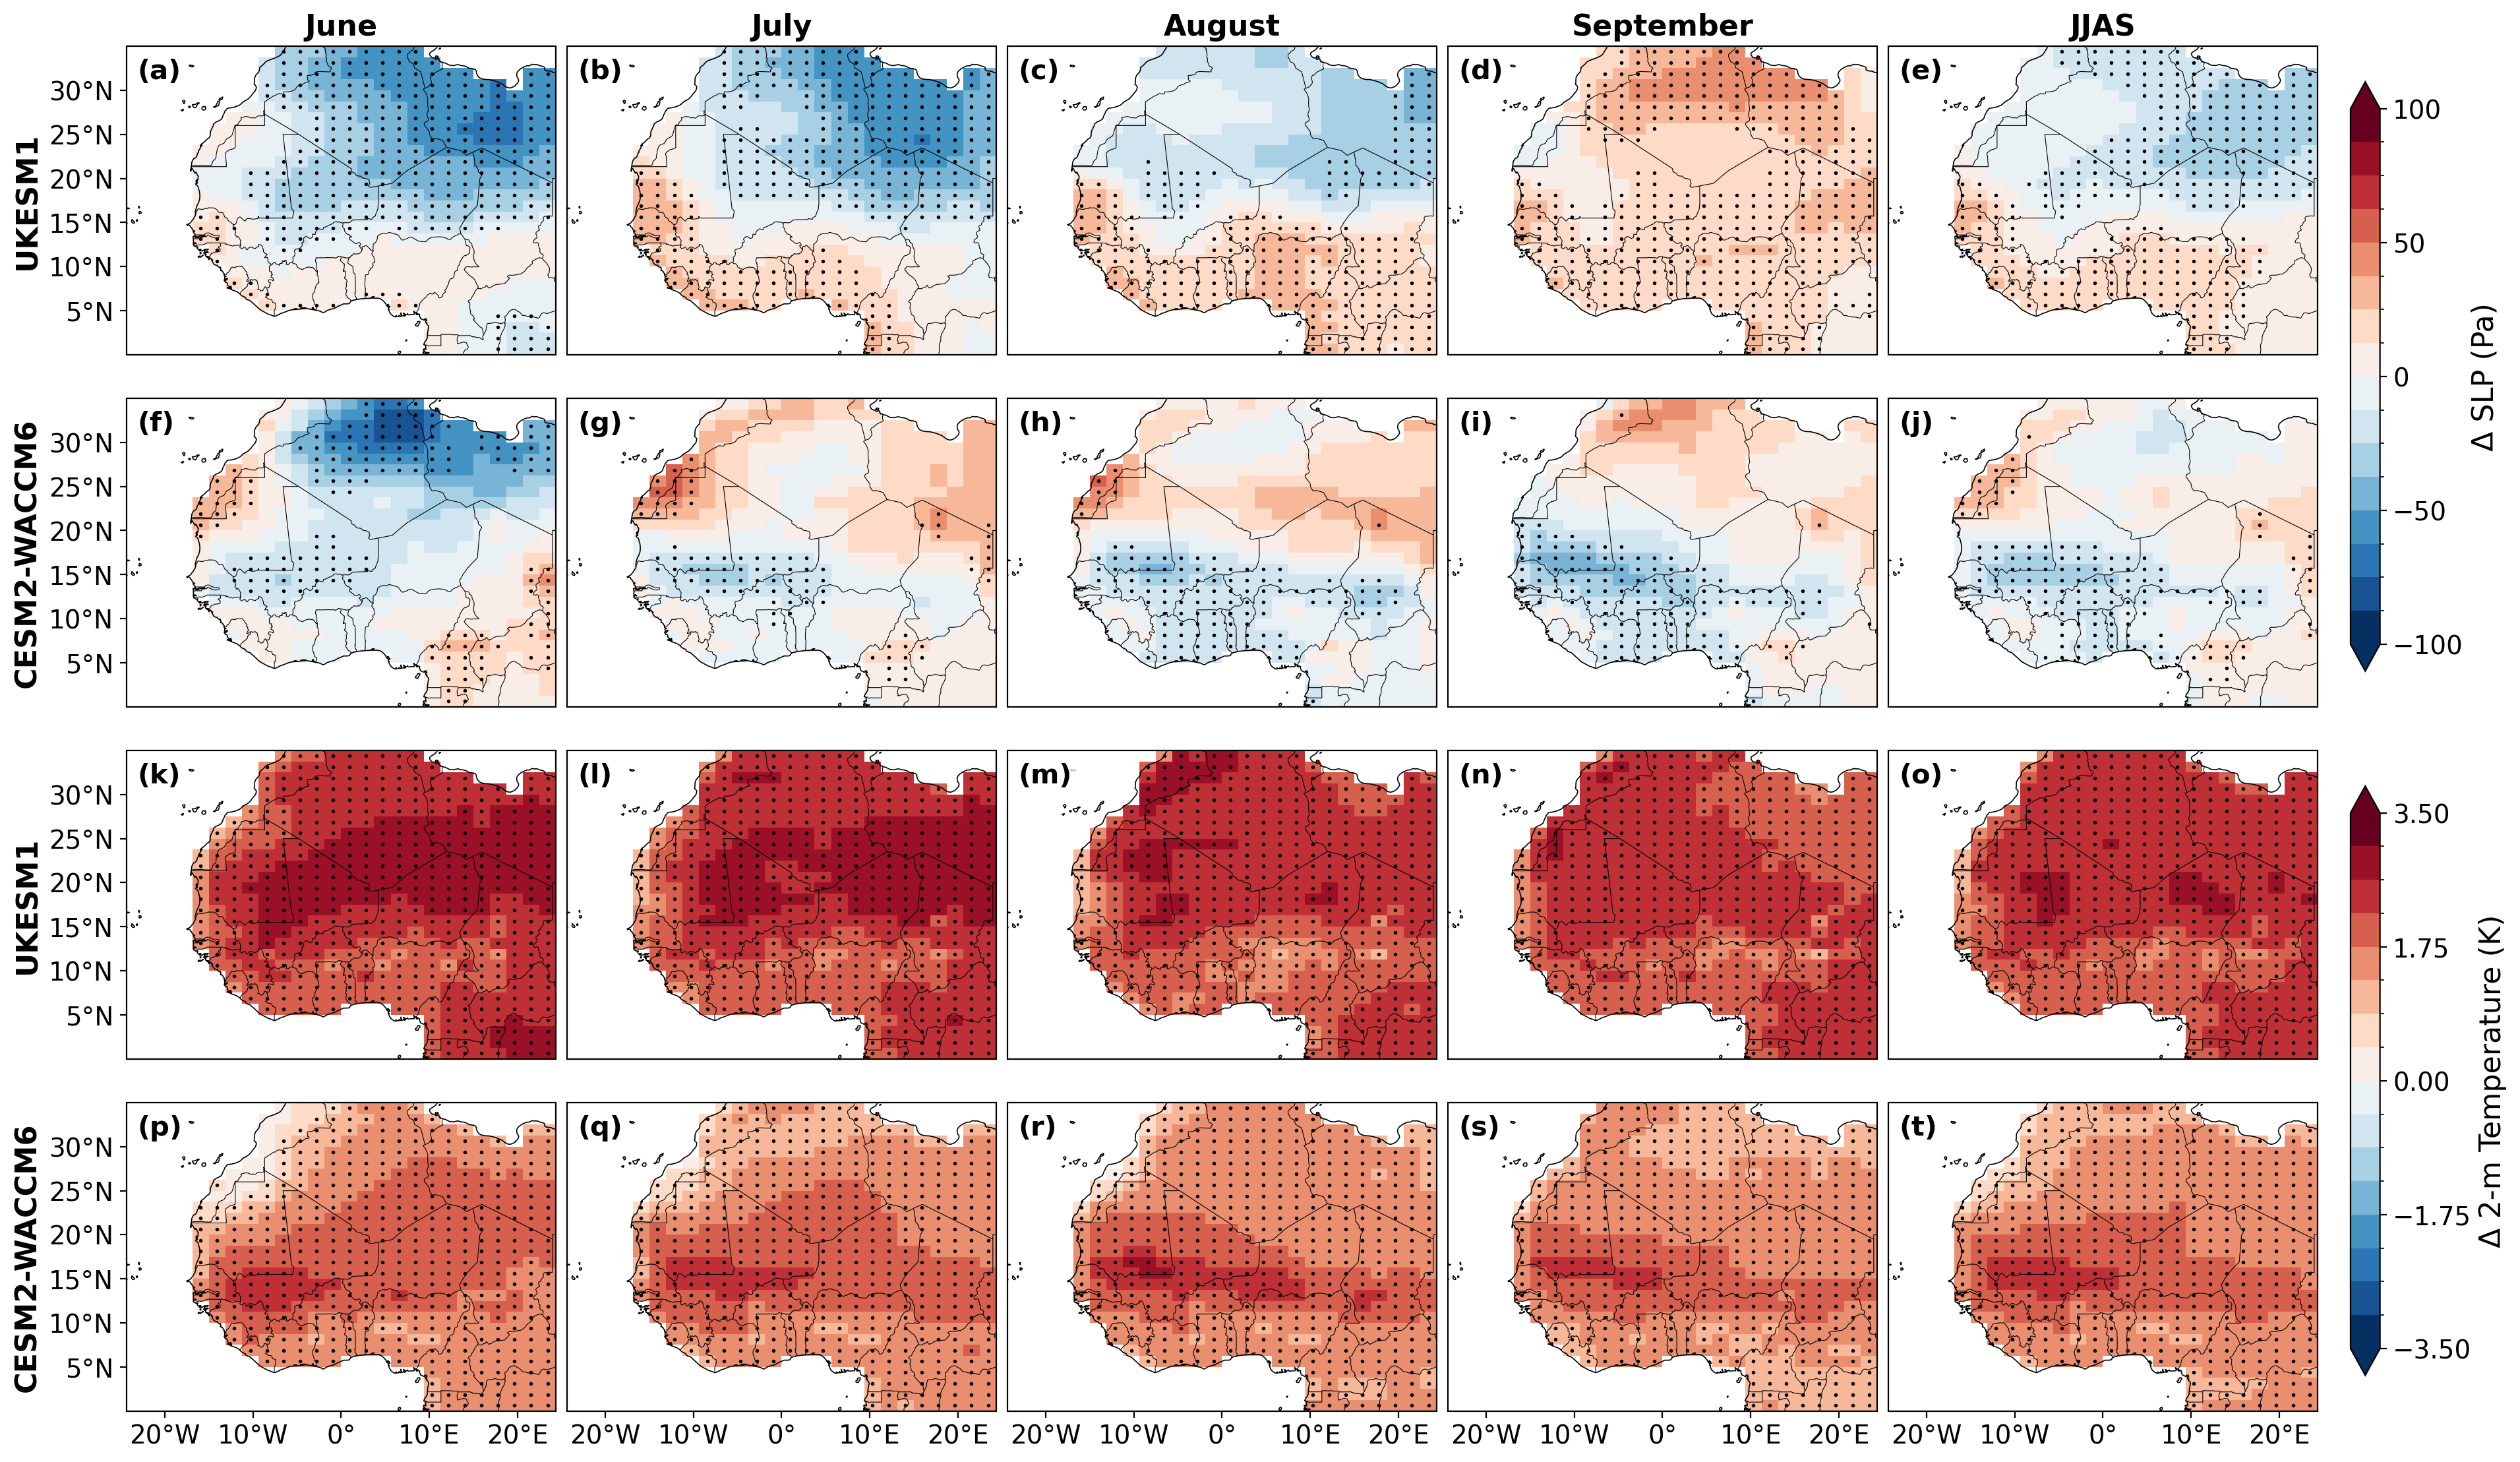

In [69]:
import string
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.colors import BoundaryNorm

import regionmask

ref = ukesm_hist['psl']
land = regionmask.defined_regions.natural_earth_v5_0_0.land_50
on_land = land.mask(ref.lon, ref.lat).notnull()

proj = ccrs.PlateCarree()
fig, axes = plt.subplots(
    4, 5, figsize=(19, 11), subplot_kw={"projection": proj}, layout="constrained"
)

for k, (var, label, unit) in enumerate([
    ("psl", "SLP", "Pa"),
    ("tas", "2-m Temperature", "K"),
]):
    peak = max(float(abs(atm_results[m, var]["diff"]).max()) for m in ("UKESM", "WACCM"))
    limit = max(0.5, np.ceil(2 * peak) / 2)
    levels = np.linspace(-limit, limit, 17) 
    levels = levels * 100 if 'SLP' in label else levels
    cmap = plt.get_cmap("RdBu_r")
    norm = BoundaryNorm(levels, cmap.N)

    for i, model in enumerate(("UKESM", "WACCM")):
        row = 2*k + i
        for col, period in enumerate(periods):
            ax = axes[row, col]
            ds = atm_results[model, var].sel(period=period).transpose("lat", "lon").where(on_land) 

            ds['diff'] = ds['diff']* 100 if 'SLP' in label else ds['diff'] 

            shading = ax.pcolormesh(
                ds.lon, ds.lat, ds["diff"], shading="auto",
                cmap=cmap, norm=norm, transform=proj,
            )
            iy, ix = np.where((ds["sig"] == 1) & ds["diff"].notnull())
            ax.scatter(ds.lon.values[ix], ds.lat.values[iy], s=4, color="black",
                       linewidths=0, transform=proj, zorder=4)

            ax.coastlines(linewidth=0.6)
            ax.add_feature(cfeature.BORDERS, linewidth=0.4)
            ax.text(
                0.025, 0.96, f"({string.ascii_lowercase[5*row + col]})",
                transform=ax.transAxes, va="top", fontweight="bold", zorder=5,fontsize=15,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
            )

            if row == 0:
                ax.set_title(period, fontweight="bold", fontsize=16)
            if col == 0:
                ax.set_ylabel(f"CESM2-{model}6", fontweight="bold", fontsize=16) if 'WACCM' in model else ax.set_ylabel(f"UKESM1", fontweight="bold", fontsize=16)
                ticks = np.arange(0, 36, 5)
                ax.set_yticks(ticks[(ticks >= float(ds.lat.min())) &
                                    (ticks <= float(ds.lat.max()))], crs=proj)
                ax.yaxis.set_major_formatter(LatitudeFormatter())
            if row == 3:
                ticks = np.arange(-20, 31, 10)
                ax.set_xticks(ticks[(ticks >= float(ds.lon.min())) &
                                    (ticks <= float(ds.lon.max()))], crs=proj)
                ax.xaxis.set_major_formatter(LongitudeFormatter())
            ax.tick_params(labelsize=14)
    cbar = fig.colorbar(
        shading, ax=axes[2*k:2*k+2, :].ravel().tolist(), location="right",
        shrink=0.85, pad=0.015, ticks=levels[::4], extend="both",
    )
    cbar.set_label(f"Δ {label} ({unit})", fontsize=16)# if 'slp' in label else cbar.set_label(f"Δ {label.upper()} ({unit})", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

# fig.suptitle("HiLLA (2035–2069) − Historical (1981–2014)", fontweight="bold")
plt.savefig('Images2/PSL_and_Temp.png',dpi=250,bbox_inches='tight')
plt.savefig('Images2/PSL_and_Temp.pdf',bbox_inches='tight')

plt.show()

### COMPUTE THE MERIDIONAL SURFACE TEMPERATURE GRADIENT

In [45]:
historical = {"ukesm": ukesm_hist, "waccm": waccm_hist}
periods = ["June", "July", "August", "September", "JJAS"]
gradient_results = {}

# Latitude is in degrees. Convert K/degree latitude to K per 100 km.
km_per_degree = np.pi * 6371.0 / 180.0

def meridional_gradient(da):
    return (da.differentiate("lat") * (100.0 / km_per_degree)).assign_attrs(
        units="K per 100 km"
    )

for model in ("ukesm", "waccm"):
    h = yearly_jjas(get_field(hilla_atm[model, "tas"], "tas"), 2035, 2069)
    b = yearly_jjas(get_field(historical[model]["tas"], "tas"), 1981, 2014)

    # One gradient map per year for each month and for the day-weighted JJAS mean.
    gh = meridional_gradient(h)
    gb = meridional_gradient(b)

    hist_mean = gb.mean("year", skipna=False)
    hilla_mean = gh.mean("year", skipna=False)
    diff = hilla_mean - hist_mean

    # Test the gradient change itself using 200 independent block draws per period.
    rng = np.random.default_rng(42)
    draws = (
        bootstrap_means(gh, rng, nboot=200, block=5)
        - bootstrap_means(gb, rng, nboot=200, block=5)
    )
    ci = draws.quantile([0.025, 0.975], dim="boot", skipna=False)
    sig = (ci.isel(quantile=0, drop=True) > 0) | (ci.isel(quantile=1, drop=True) < 0)

    gradient_results[model] = xr.Dataset({
        "historical": hist_mean,
        "hilla": hilla_mean,
        "diff": diff,
        "sig": sig,
    })

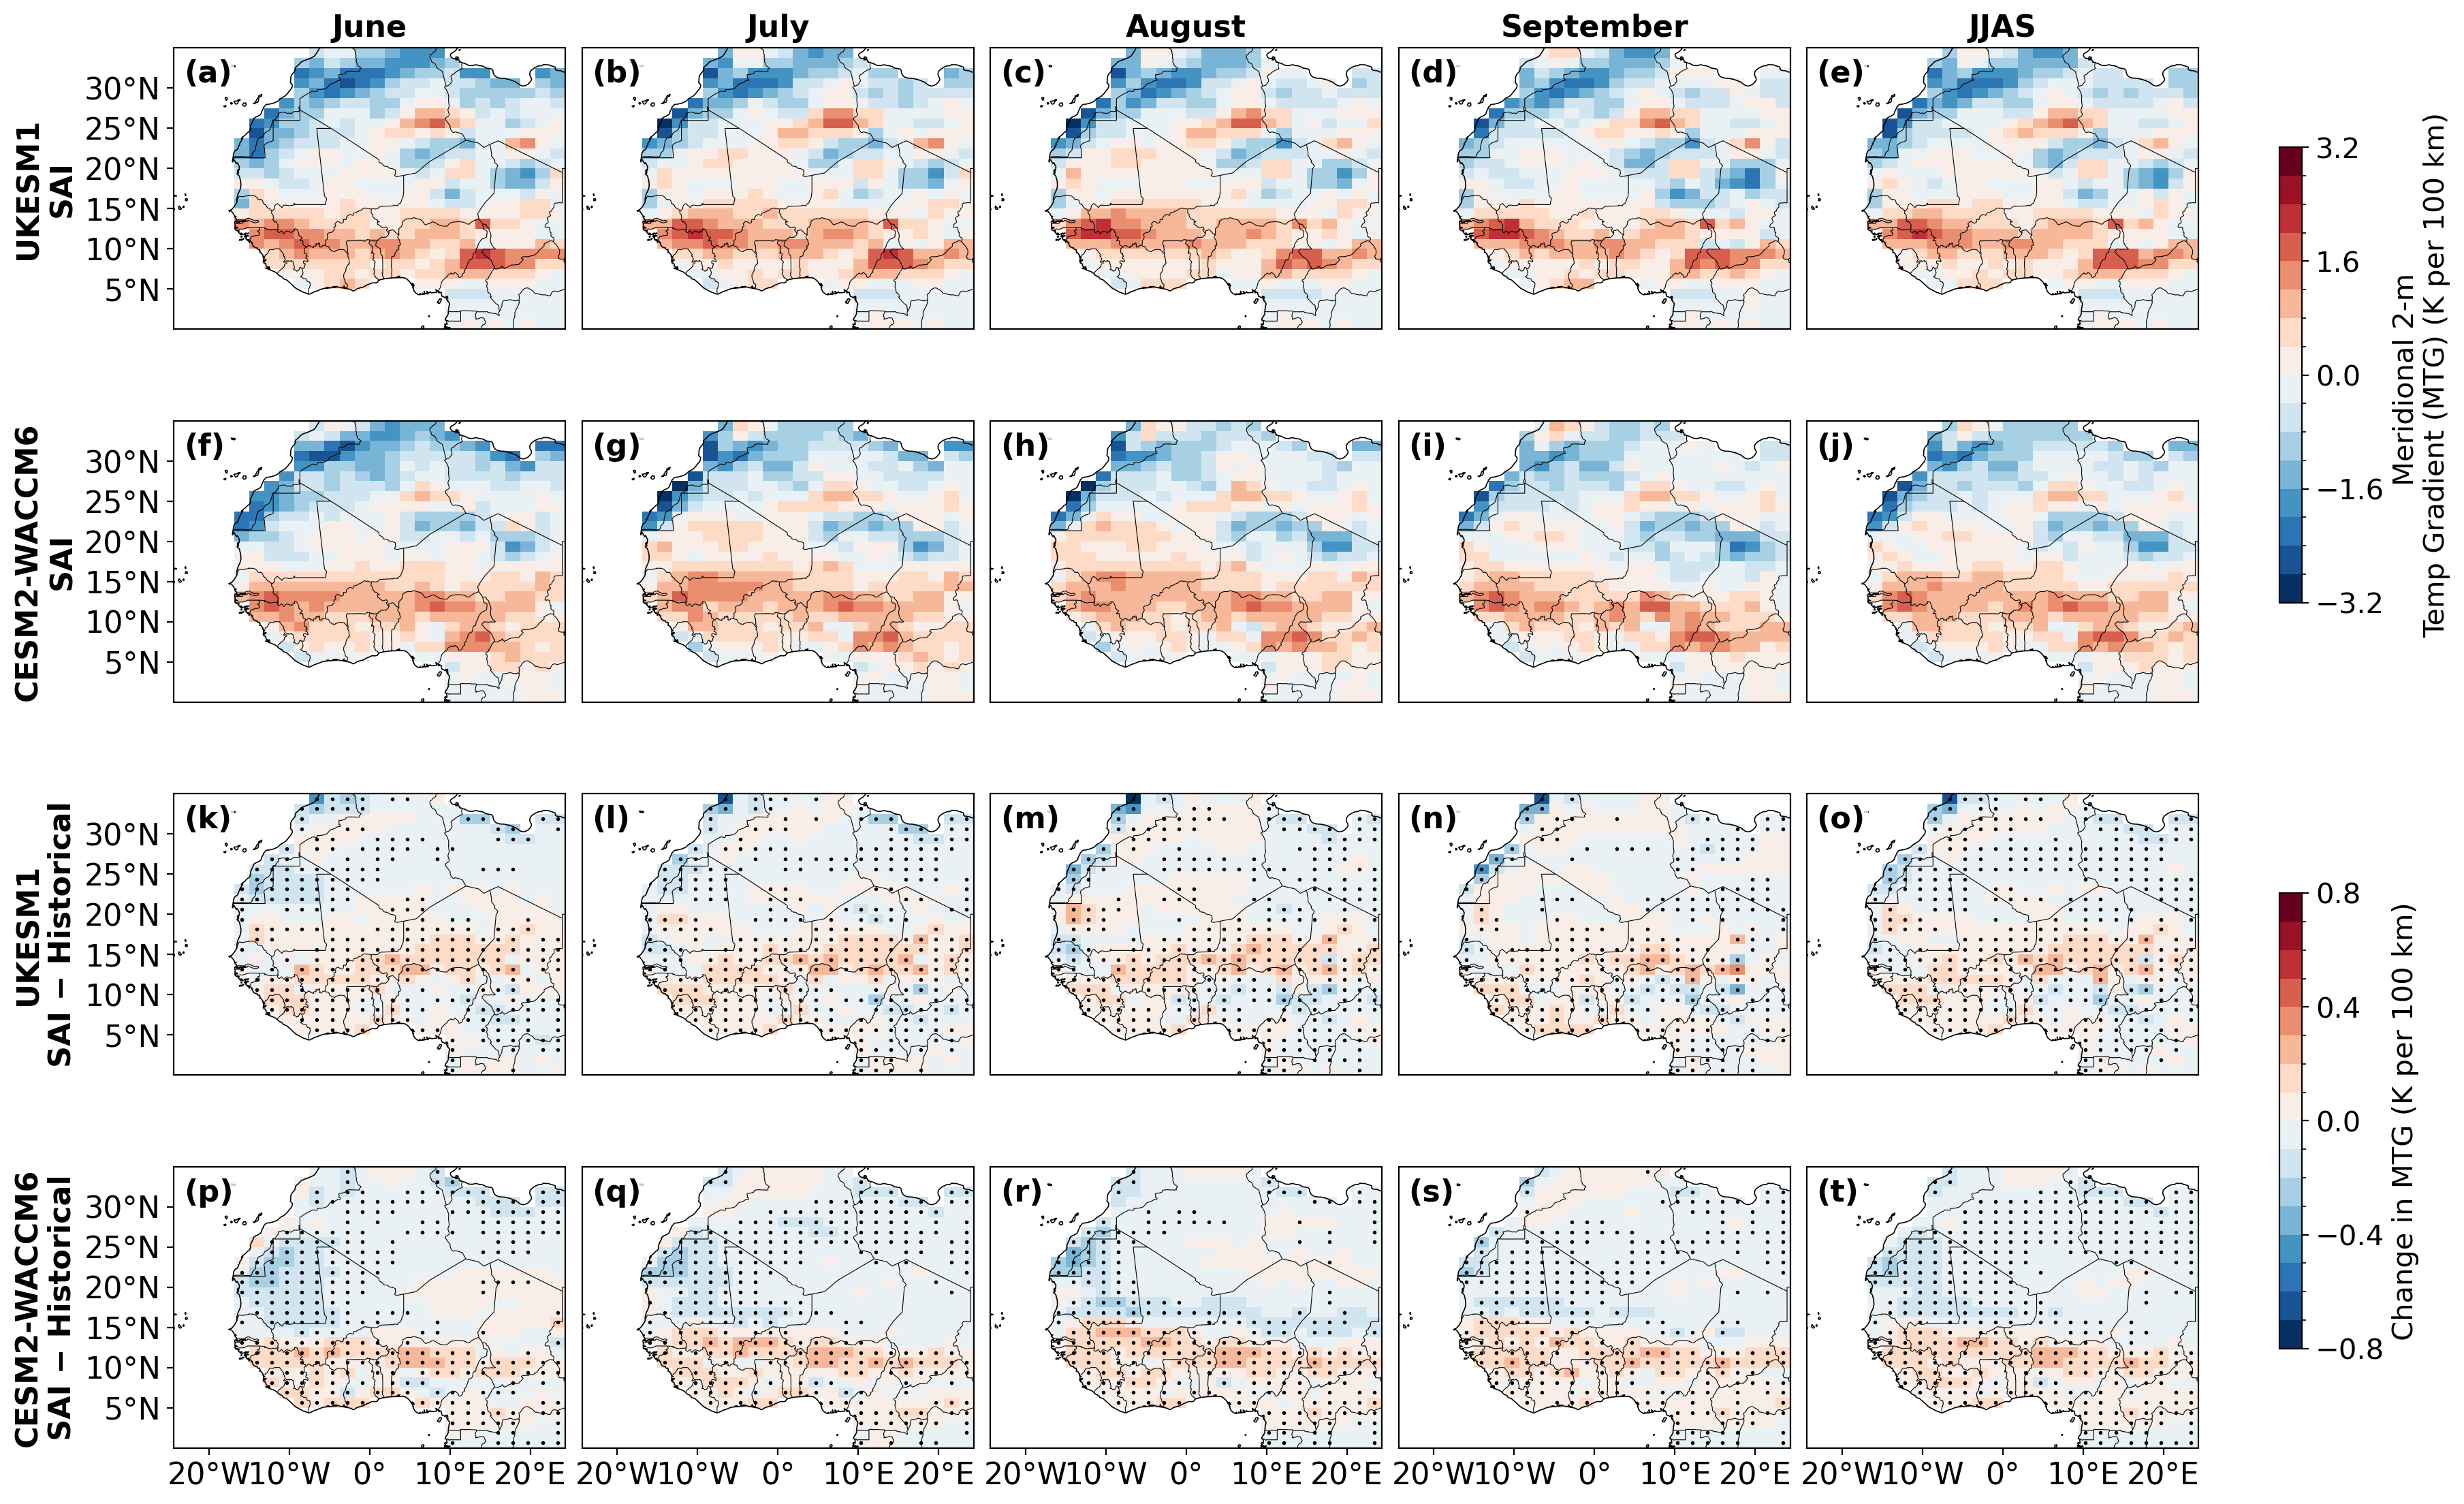

In [68]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import regionmask
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.colors import BoundaryNorm

models = [("ukesm", "UKESM"), ("waccm", "WACCM")]
periods = ["June", "July", "August", "September", "JJAS"]
proj = ccrs.PlateCarree()
cmap = plt.get_cmap("RdBu_r")

ref = gradient_results["ukesm"]["hilla"]
land = regionmask.defined_regions.natural_earth_v5_0_0.land_50
on_land = land.mask(ref.lon, ref.lat).notnull()

fig, axes = plt.subplots(
    4, 5, figsize=(18, 11), subplot_kw={"projection": proj},
    layout="constrained",
)

for k, (key, row_label, bar_label) in enumerate([
    ("hilla", "SAI", "Meridional 2-m \nTemp Gradient (MTG)"),
    ("diff", "SAI − Historical", "Change in MTG"),
]):
    # Use all ten land panels in this group to set one symmetric color scale.
    peak = max(
        float(abs(gradient_results[model][key].where(on_land)).max())
        for model, _ in models
    )
    limit = max(0.1, np.ceil(peak * 10) / 10)
    levels = np.linspace(-limit, limit, 17)
    norm = BoundaryNorm(levels, cmap.N)

    for i, (model, name) in enumerate(models):
        row = 2 * k + i

        for col, period in enumerate(periods):
            ax = axes[row, col]
            ds = gradient_results[model].sel(period=period).transpose("lat", "lon")
            field = ds[key].where(on_land)

            shading = ax.pcolormesh(
                ds.lon, ds.lat, field, shading="auto",
                cmap=cmap, norm=norm, transform=proj,
            )

            # The bootstrap tested HiLLA − Historical, so stipple those rows only.
            if key == "diff":
                sig_land = (ds["sig"] == 1) & field.notnull()
                iy, ix = np.where(sig_land.values)
                ax.scatter(
                    ds.lon.values[ix], ds.lat.values[iy],
                    s=4, color="black", linewidths=0, transform=proj, zorder=4,
                )

            ax.coastlines(linewidth=0.6)
            ax.add_feature(cfeature.BORDERS, linewidth=0.4)
            ax.text(
                0.025, 0.96, f"({chr(97 + 5*row + col)})",
                transform=ax.transAxes, va="top", fontweight="bold", zorder=5,fontsize=16,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
            )

            if row == 0:
                ax.set_title(period, fontweight="bold",fontsize=16,)
            if col == 0:
                ax.set_ylabel(f"CESM2-{name}6\n{row_label}", fontweight="bold",fontsize=16,) if 'WACCM' in name else ax.set_ylabel(f"{name}1\n{row_label}", fontweight="bold",fontsize=16,) 
                ticks = np.arange(0, 36, 5)
                ax.set_yticks(ticks[(ticks >= float(ds.lat.min())) &
                                    (ticks <= float(ds.lat.max()))], crs=proj)
                ax.yaxis.set_major_formatter(LatitudeFormatter())
            if row == 3:
                ticks = np.arange(-20, 31, 10)
                ax.set_xticks(ticks[(ticks >= float(ds.lon.min())) &
                                    (ticks <= float(ds.lon.max()))], crs=proj)
                ax.xaxis.set_major_formatter(LongitudeFormatter())
            ax.tick_params(labelsize=16)
    cbar = fig.colorbar(
        shading, ax=axes[2*k:2*k + 2, :].ravel().tolist(),
        location="right", shrink=0.62, pad=0.04, ticks=levels[::4],
    )
    cbar.set_label(f"{bar_label} (K per 100 km)", fontsize=15)
    cbar.ax.tick_params(labelsize=15)

# fig.suptitle("Meridional temperature gradient under HiLLA (2035–2069) "
             # "and change from Historical (1981–2014)")
plt.savefig('Images2/MTG_figure_new.png',dpi=250,bbox_inches='tight')
plt.savefig('Images2/MTG_figure_new.pdf',bbox_inches='tight')

plt.show()

### THE AEJ LOCATION

In [70]:
# temp_var = "tas"
variables = ["ua"]
catalog = pd.read_csv("https://cmip6-pds.s3.amazonaws.com/pangeo-cmip6.csv")


def open_hist_ensemble_mean(source):
    rows = catalog.query(
        "activity_id == 'CMIP' and source_id == @source and "
        "experiment_id == 'historical' and table_id == 'Amon' and "
        "grid_label == 'gn' and variable_id in @variables"
    ).drop_duplicates("zstore").copy()

    # Keep the latest catalog version of each member-variable pair.
    rows["release"] = rows["zstore"].str.extract(r"/v(\d{8})(?:/|$)", expand=False)
    if "version" in rows:
        version = rows["version"].astype(str).str.extract(r"(\d{8})", expand=False)
        rows["release"] = rows["release"].fillna(version)

    keys = ["member_id", "variable_id"]
    duplicates = rows.duplicated(keys, keep=False)
    if rows.loc[duplicates, "release"].isna().any():
        raise ValueError(f"{source}: could not resolve duplicate catalog versions.")

    rows = rows.sort_values("release").drop_duplicates(keys, keep="last")
    stores = rows.pivot(index="member_id", columns="variable_id", values="zstore")
    stores = stores.reindex(columns=variables).dropna()
    if stores.empty:
        raise ValueError(f"{source}: no members with both {variables}.")

    # Use the same members for pressure and temperature within this model.
    members = []
    for member, paths in stores.iterrows():
        fields = []
        for var in variables:
            da = xr.open_zarr(
                paths[var], consolidated=True, chunks={}, storage_options={"anon": True}
            )[var]

            da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
            da = da.sortby("lon").sortby("lat").sel(
                time=slice("1981", "2014"), lon=slice(-25, 25), lat=slice(0, 35)
            )
            da = da.sel(time=da.time.dt.month.isin([6, 7, 8, 9]))
            fields.append(da)

        members.append(xr.merge(fields, join="exact").expand_dims(member=[member]))

    ensemble = xr.concat(members, dim="member", join="exact")

    # Verify one value per JJAS month in each of the 34 years.
    expected = [100 * y + m for y in range(1981, 2015) for m in (6, 7, 8, 9)]
    actual = ensemble.time.dt.year * 100 + ensemble.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{source}: incomplete or unordered JJAS time axis.")

    print(f"{source}: averaging {len(stores)} members: {', '.join(stores.index)}")
    return ensemble.mean("member", skipna=False, keep_attrs=True).load()


waccm_hist = open_hist_ensemble_mean("CESM2-WACCM")
ukesm_hist = open_hist_ensemble_mean("UKESM1-0-LL")

CESM2-WACCM: averaging 3 members: r1i1p1f1, r2i1p1f1, r3i1p1f1
UKESM1-0-LL: averaging 18 members: r10i1p1f2, r11i1p1f2, r12i1p1f2, r13i1p1f2, r14i1p1f2, r16i1p1f2, r17i1p1f2, r18i1p1f2, r19i1p1f2, r1i1p1f2, r2i1p1f2, r3i1p1f2, r4i1p1f2, r5i1p1f3, r6i1p1f3, r7i1p1f3, r8i1p1f2, r9i1p1f2


In [72]:
import numpy as np
import xarray as xr

sim_time = slice("2035", "2069")
months = [6, 7, 8, 9]
periods = ["June", "July", "August", "September", "JJAS"]
bucket = "reflective-persistent-prod-large"


def select_hilla_months(obj, var):
    da = obj[var] if isinstance(obj, xr.Dataset) else obj

    # Use the start of the monthly averaging interval when bounds are available.
    if isinstance(obj, xr.Dataset):
        for name in (obj.time.attrs.get("bounds"), "time_bnds", "time_bounds"):
            if name and name in obj:
                bounds = obj[name]
                edge = next(d for d in bounds.dims if d != "time")
                da = da.assign_coords(time=bounds.isel({edge: 0}).values)
                break

    da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
    da = da.sortby("lon").sortby("lat").sortby("time")
    da = da.sel(time=sim_time, lon=slice(-25, 30), lat=slice(0, 35))
    da = da.sel(time=da.time.dt.month.isin(months))

    expected = [100 * y + m for y in range(2035, 2070) for m in months]
    actual = da.time.dt.year * 100 + da.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{var}: expected one value per JJAS month for 2035–2069.")
    return da


def open_hilla_mean(model, variable):
    members = (
        ["r12i1p1f2", "r2i1p1f2", "r3i1p1f2"]
        if model == "ukesm" else ["r1", "r2", "r3"]
    )
    arrays = []

    for member in members:
        if model == "ukesm":
            stream, table = {
                "psl": ("ap5", "Amon"),
                "tas": ("apm", "Amon"),
                "ua":  ("ap4", "AERmon"),
            }[variable]

            var = variable
            obj = open_s3_xarray_ukesm(
                bucket=bucket,
                group="UKESM1-1",
                scenario=f"G6-1p5K-HiLLA/{member}/{stream}/{table}/{var}",
                variable_name=var,
                partial_filename=f"{table}_UKESM1-1-LL_g6-1p5-hilla_{member}_gn",
            )
        else:
            var = {"psl": "PSL", "tas": "TREFHT", "ua": "U"}[variable]
            number = int(member[1:])
            obj = open_s3_xarray_waccm(
                bucket=bucket,
                group="CESM2-WACCM",
                scenario=(
                    f"G6-1.5k-HiLLA/{member}/AMON/"
                    f"b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.{number:03d}.cam.h0."
                ),
                variable_name=var,
                partial_filename="",
                anon1=False,
            )

        arrays.append(select_hilla_months(obj, var))

    ensemble = xr.concat(arrays, dim=xr.IndexVariable("member", members), join="exact")
    return ensemble.mean("member", skipna=False, keep_attrs=True).load()


# hilla_atm = {
#     (model, var): open_hilla_mean(model, var)
#     for model in ("ukesm", "waccm")
#     for var in ("psl", "tas")
# }

In [73]:
for model in ("ukesm", "waccm"):
    wind = open_hilla_mean(model, "ua")
    hilla_atm[model, "ua"] = wind
    print(model, dict(wind.sizes), wind.attrs.get("units"))

reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r12i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


lat
reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r2i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


lat
reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r3i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r3i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


... (3 outputs left out)

/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat
['simplecache::s3://reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.U.203501-208412.nc']
reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.U*.nc


/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat
waccm {'time': 140, 'lev': 70, 'lat': 37, 'lon': 45} m/s


In [76]:
# =========================================
# Approximate height → pressure
# Input: meters; output: Pa
# Valid here for nominal heights 0–20 km
# =========================================
def height_to_pressure(height):
    z = np.asarray(height, dtype=float)

    p = np.full(z.shape, np.nan, dtype=float)

    # Standard-atmosphere troposphere.
    lower = (z >= 0) & (z <= 11000)
    p[lower] = 101325.0 * (
        1 - 0.0065 * z[lower] / 288.15
    ) ** 5.25588

    # Isothermal layer above 11 km.
    upper = (z > 11000) & (z <= 20000)
    p[upper] = 22632.06 * np.exp(
        -9.80665 * (z[upper] - 11000) / (287.05 * 216.65)
    )

    return p

/srv/conda/envs/notebook/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/srv/conda/envs/notebook/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


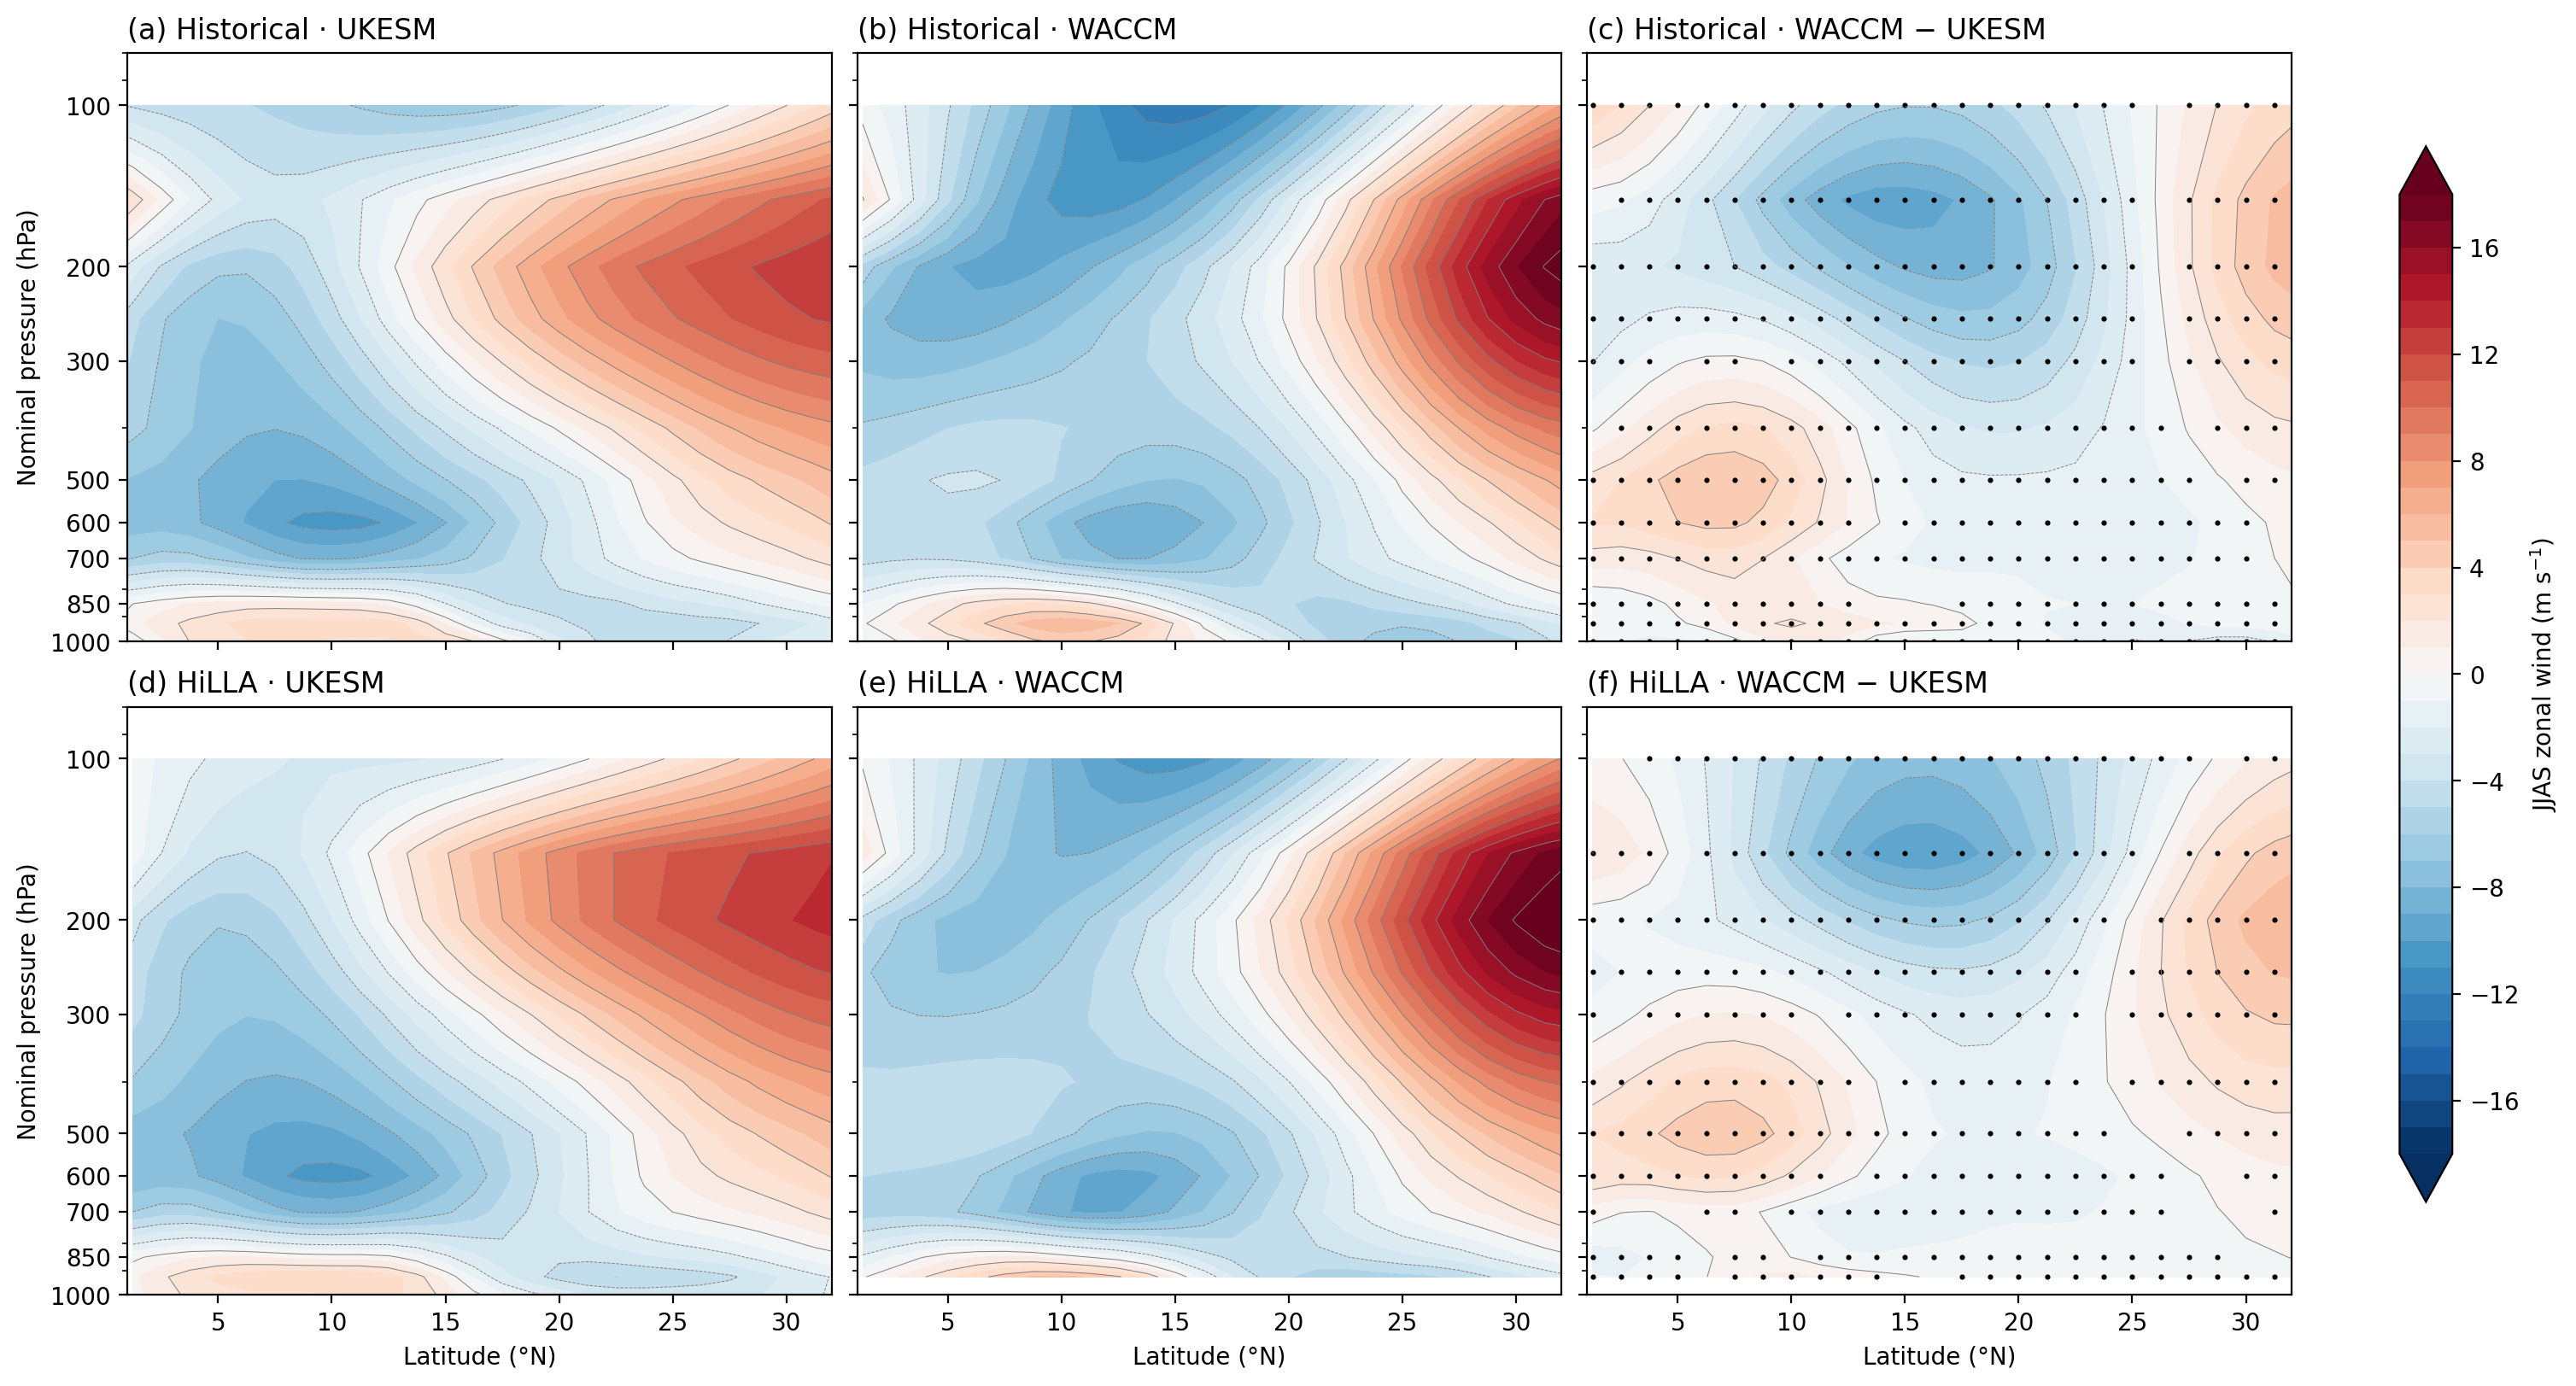

In [77]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from matplotlib.ticker import ScalarFormatter, NullFormatter
from pathlib import Path

# HiLLA winds from your loader; historical winds from your existing datasets.
winds = {
    "Historical": {
        "UKESM": ukesm_hist["ua"],
        "WACCM": waccm_hist["ua"],
    },
    "HiLLA": {
        "UKESM": hilla_atm["ukesm", "ua"],
        "WACCM": hilla_atm["waccm", "ua"],
    },
}
def annual_section(u, model, experiment):
    # Apply the same longitude range before taking either model's zonal mean.
    u = u.assign_coords(lon=((u.lon + 180) % 360) - 180).sortby("lon")
    u = u.sel(lon=slice(-25, 25)).mean("lon")
    dates = slice("1981", "2014") if experiment == "Historical" else slice("2035", "2069")
    u = u.sel(time=dates)
    u = u.sel(time=u.time.dt.month.isin([6, 7, 8, 9]))

    if experiment == "Historical":
        u = u.rename(plev="lev").assign_coords(lev=u.plev.values / 100)  # Pa → hPa
    elif model == "UKESM":
        u = u.assign_coords(lev=height_to_pressure(u.lev.values) / 100)
    # WACCM HiLLA retains its supplied nominal hPa levels, as in your example.
    u = u.isel(lev=np.isfinite(u.lev)).sortby("lev").sortby("lat")

    days = u.time.dt.days_in_month
    return ((u * days).groupby("time.year").sum("time", skipna=False)
            / days.groupby("time.year").sum("time"))


annual = {
    (exp, model): annual_section(u, model, exp)
    for exp, pair in winds.items() for model, u in pair.items()
}

# Use one latitude–pressure grid for all six panels.
ref = annual["Historical", "UKESM"]
grid = {"lat": ref.lat, "lev": ref.lev.sel(lev=slice(80, 1000))}
annual = {key: u.interp(grid).transpose("year", "lev", "lat").compute()
          for key, u in annual.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True,
                         layout="constrained")
levels = np.arange(-18, 19, 1)

for i, exp in enumerate(("Historical", "HiLLA")):
    uk, wa = annual[exp, "UKESM"], annual[exp, "WACCM"]
    uk_mean, wa_mean = uk.mean("year"), wa.mean("year")
    diff = wa_mean - uk_mean
    p = ttest_ind(wa.values, uk.values, axis=0, equal_var=False,
                  nan_policy="omit").pvalue

    for j, (title, field) in enumerate(zip(
        ("UKESM", "WACCM", "WACCM − UKESM"), (uk_mean, wa_mean, diff)
    )):
        ax = axes[i, j]
        im = ax.contourf(field.lat, field.lev, field, levels=levels,
                         cmap="RdBu_r", extend="both")
        ax.contour(field.lat, field.lev, field, levels=levels[::2],
                   colors="grey", linewidths=0.35)

        if j == 2:
            iz, iy = np.where(p < 0.05)
            ax.scatter(field.lat.values[iy], field.lev.values[iz],
                       s=5, color="black", linewidths=0)

        ax.set_title(f"({chr(97 + 3*i + j)}) {exp} · {title}", loc="left")
        ax.set_yscale("log")
        ax.set_ylim(1000, 80)
        ax.set_yticks([100, 200, 300, 500, 600, 700, 850, 1000])
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_xlim(1, 32)
        ax.set_xticks([5, 10, 15, 20, 25, 30])
        if i == 1:
            ax.set_xlabel("Latitude (°N)")
        if j == 0:
            ax.set_ylabel("Nominal pressure (hPa)")

fig.colorbar(im, ax=axes, shrink=0.85, ticks=np.arange(-16, 17, 4),
             label=r"JJAS zonal wind (m s$^{-1}$)")
Path("Images").mkdir(exist_ok=True)
# fig.savefig("Images/AEJ_zonal_winds_cross_section_HIST_SAI.png", dpi=250)
plt.show()

In [79]:

from matplotlib.ticker import ScalarFormatter, NullFormatter
from scipy.stats import ttest_ind
from pathlib import Path

models = ["UKESM", "WACCM"]
months = [6, 7, 8, 9]
periods = ["June", "July", "August", "September", "JJAS"]

winds = {
    ("UKESM", "HiLLA"): hilla_atm["ukesm", "ua"],
    ("WACCM", "HiLLA"): hilla_atm["waccm", "ua"],
    ("UKESM", "Historical"): ukesm_hist["ua"],
    ("WACCM", "Historical"): waccm_hist["ua"],
}


def wind_sections(u, model, experiment):
    """Return one latitude–pressure section per year for each month and JJAS."""
    start, end = (2035, 2069) if experiment == "HiLLA" else (1981, 2014)

    # Use the same longitude sector in both experiments.
    u = u.assign_coords(lon=((u.lon + 180) % 360) - 180).sortby("lon")
    u = u.sel(lon=slice(-25, 25), time=slice(str(start), str(end))).mean("lon")
    u = u.sel(time=u.time.dt.month.isin(months)).sortby("time")

    expected = [100*y + m for y in range(start, end + 1) for m in months]
    if not np.array_equal((100*u.time.dt.year + u.time.dt.month).values, expected):
        raise ValueError(f"{model} {experiment}: missing or duplicate JJAS months.")

    # Follow the vertical-coordinate conventions in your original wind figure.
    if experiment == "Historical":
        u = u.rename({"plev": "lev"})
        u = u.assign_coords(lev=u.lev / 100)                   # Pa → hPa
    elif model == "UKESM":
        u = u.assign_coords(lev=height_to_pressure(u.lev) / 100)
    # WACCM HiLLA retains its supplied nominal hPa levels.
    u = u.isel(lev=np.isfinite(u.lev)).sortby("lev").sortby("lat")

    monthly = []
    for month in months:
        one = u.sel(time=u.time.dt.month == month)
        monthly.append(one.assign_coords(time=one.time.dt.year).rename(time="year"))

    days = u.time.dt.days_in_month
    jjas = ((u * days).groupby("time.year").sum("time", skipna=False)
            / days.groupby("time.year").sum("time"))

    return xr.concat([*monthly, jjas], dim=xr.IndexVariable("period", periods),
                     join="exact")


annual = {key: wind_sections(u, *key) for key, u in winds.items()}

# Use the historical pressure levels and UKESM latitudes for all four rows.
ref = annual["UKESM", "Historical"]
grid = {"lat": ref.lat, "lev": ref.lev.sel(lev=slice(80, 1000))}
annual = {
    key: da.interp(grid).transpose("year", "period", "lev", "lat").compute()
    for key, da in annual.items()
}

results = {}
for model in models:
    sai = annual[model, "HiLLA"]
    hist = annual[model, "Historical"]
    sai_mean = sai.mean("year")
    diff = sai_mean - hist.mean("year")

    # Compare annual June values with annual June values, and likewise for JJAS.
    p = ttest_ind(sai.values, hist.values, axis=0,
                  equal_var=False, nan_policy="omit").pvalue

    results[model] = xr.Dataset({
        "sai": sai_mean,
        "diff": diff,
        "sig": (diff.dims, p < 0.05),
    })

/srv/conda/envs/notebook/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/srv/conda/envs/notebook/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_13447/3398385756.py:46: SyntaxWarning: invalid escape sequence '\D'
  label = "zonal wind" if key == "sai" else "$\Delta$ zonal wind"


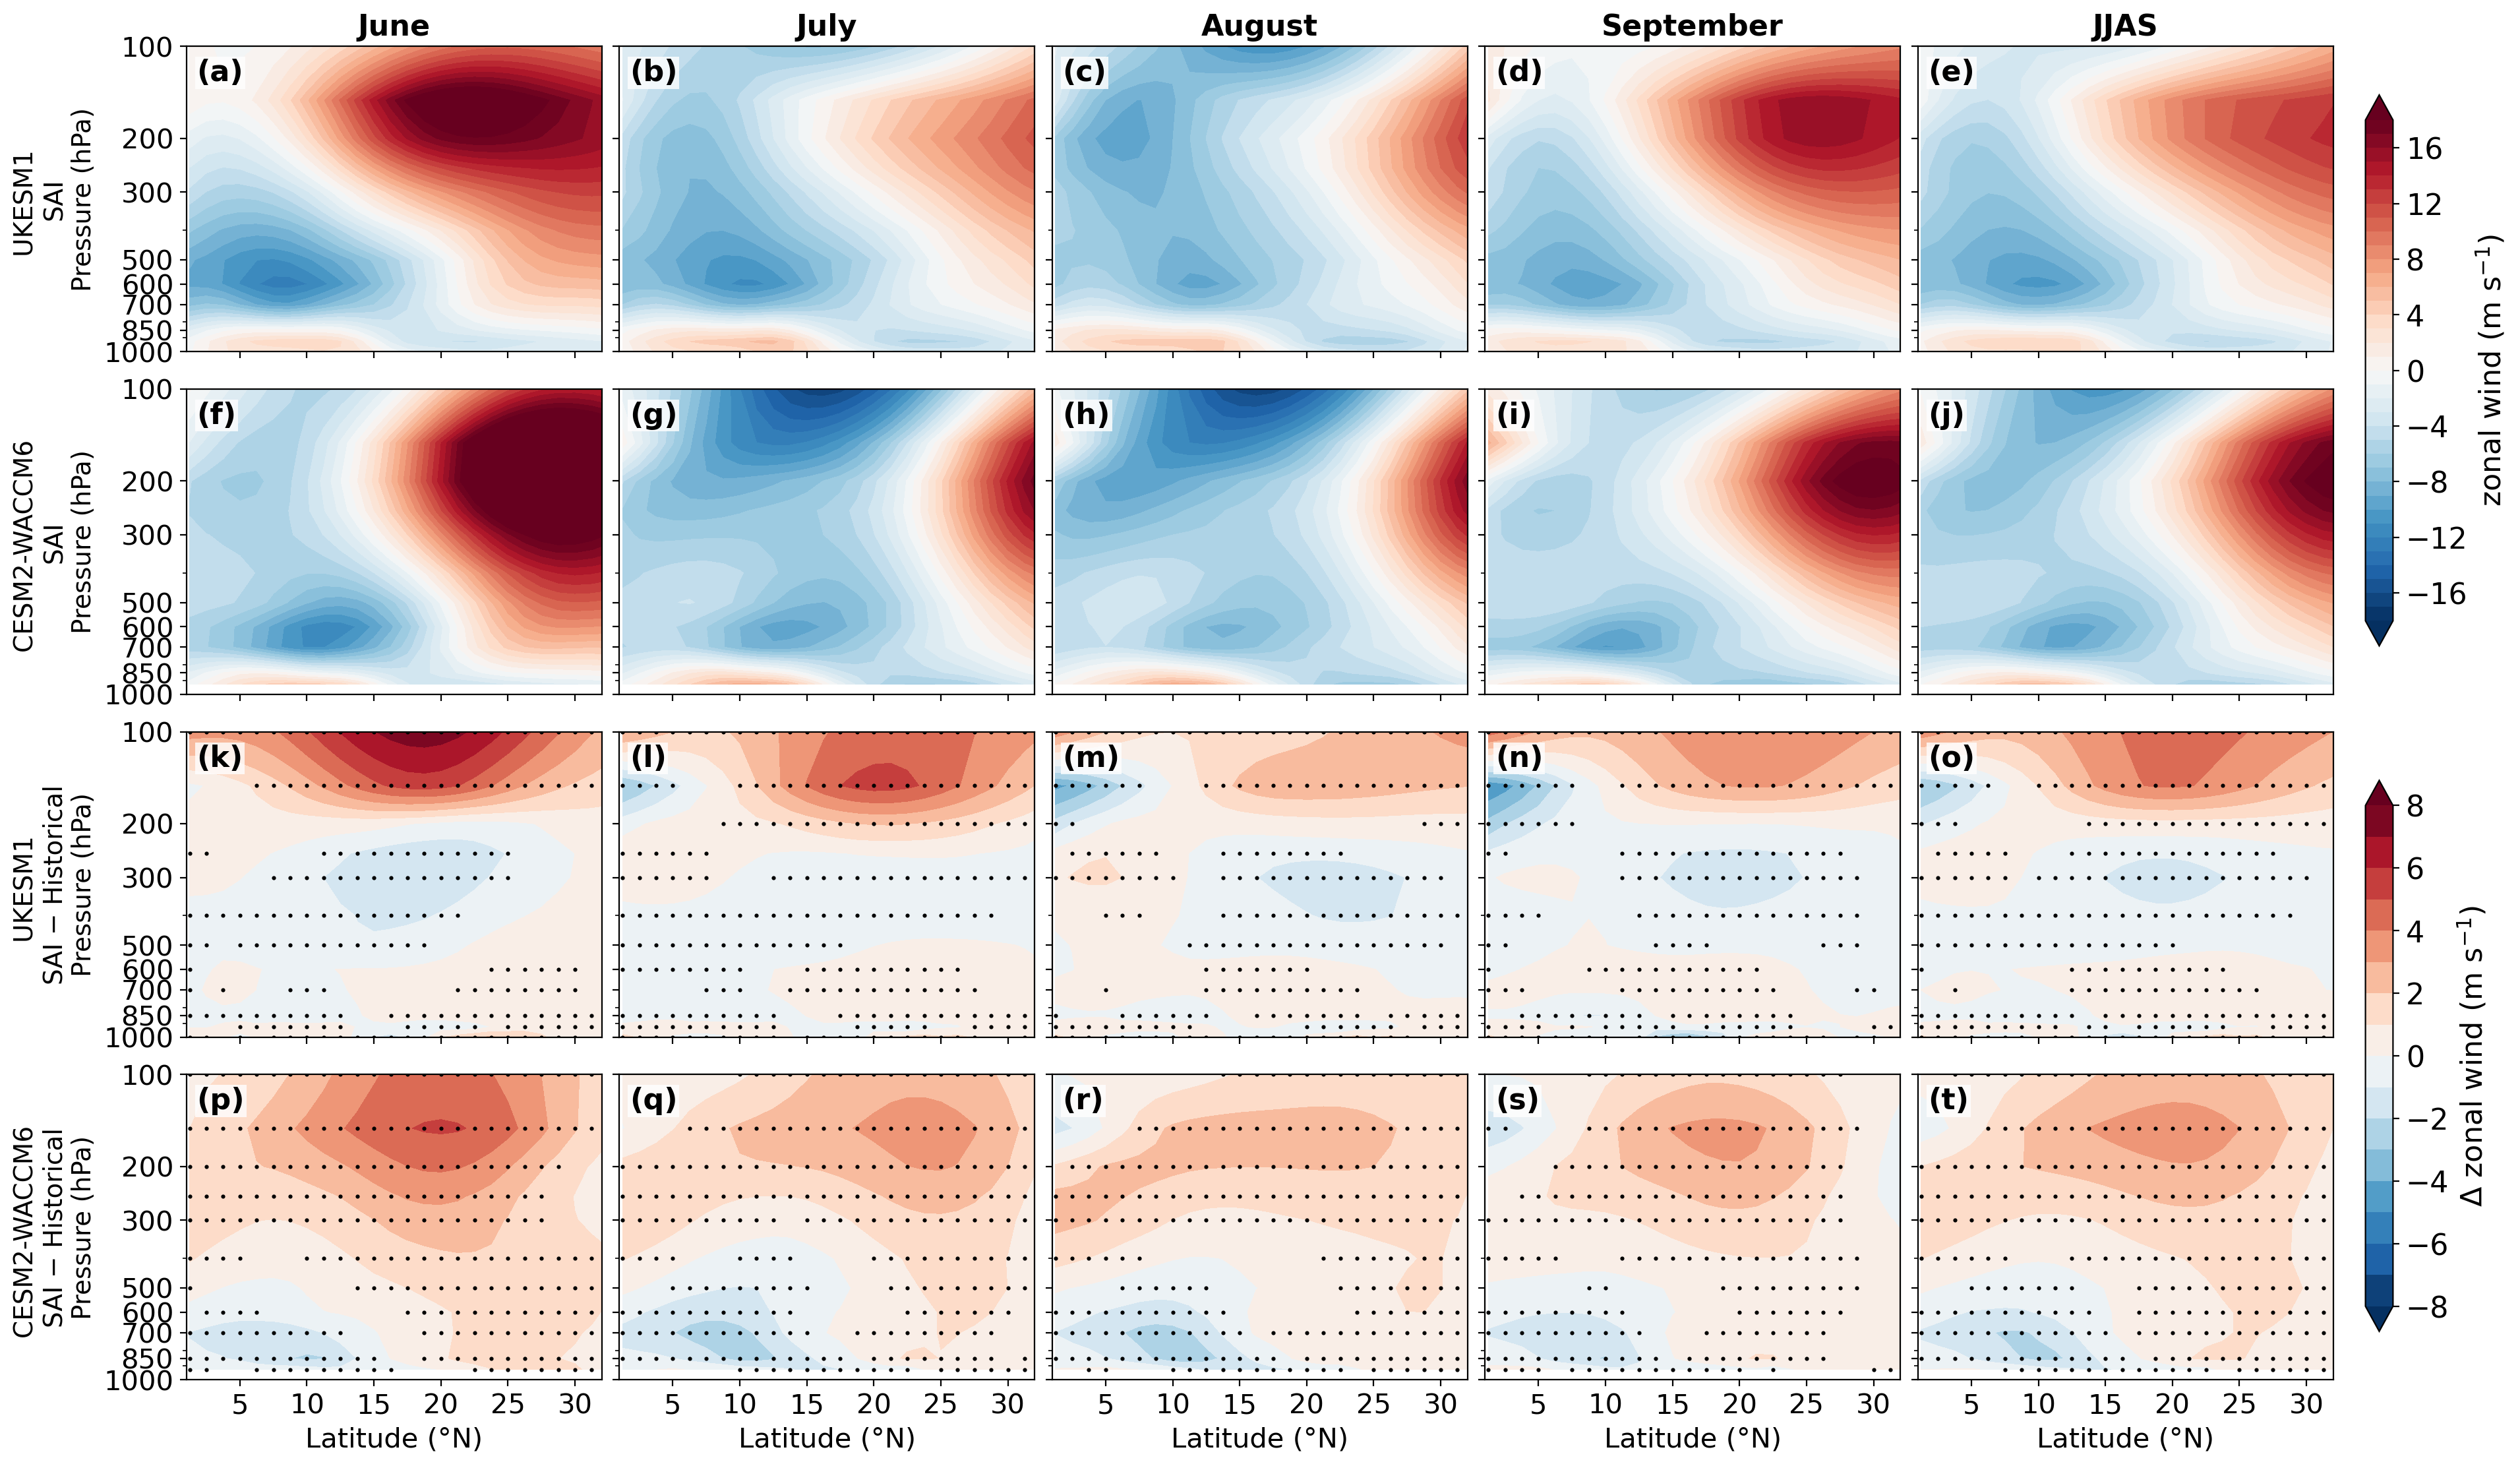

In [93]:
fig, axes = plt.subplots(4, 5, figsize=(19, 11), sharex=True, sharey=True,
                         layout="constrained")

wind_levels = np.arange(-18, 19, 1)
peak = max(float(abs(results[m]["diff"]).max()) for m in models)
diff_limit = max(1, np.ceil(peak))
diff_levels = np.linspace(-diff_limit, diff_limit, 17)

for k, (key, row_label, levels) in enumerate([
    ("sai", "SAI", wind_levels),
    ("diff", "SAI − Historical", diff_levels),
]):
    for i, model in enumerate(models):
        row = 2*k + i
        for col, period in enumerate(periods):
            ax = axes[row, col]
            ds = results[model].sel(period=period)
            field = ds[key].transpose("lev", "lat")

            shading = ax.contourf(field.lat, field.lev, field, levels=levels,
                                  cmap="RdBu_r", extend="both")

            if key == "diff":
                iz, iy = np.where(ds["sig"].transpose("lev", "lat"))
                ax.scatter(field.lat.values[iy], field.lev.values[iz],
                           s=5, color="black", linewidths=0)

            ax.set_yscale("log")
            ax.set_ylim(1000, 100)
            ax.set_yticks([100, 200, 300, 500, 600, 700, 850, 1000])
            ax.yaxis.set_major_formatter(ScalarFormatter())
            ax.yaxis.set_minor_formatter(NullFormatter())
            ax.set_xlim(1, 32)
            ax.set_xticks([5, 10, 15, 20, 25, 30])

            ax.text(0.025, 0.96, f"({chr(97 + 5*row + col)})",
                    transform=ax.transAxes, va="top", fontweight="bold", fontsize=16,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
            if row == 0:
                ax.set_title(period, fontweight="bold", fontsize=16)
            if col == 0:
                ax.set_ylabel(f"CESM2-{model}6 \n{row_label}\nPressure (hPa)", fontsize=14) if 'WACCM' in model else ax.set_ylabel(f"{model}1 \n{row_label}\nPressure (hPa)", fontsize=14)
            if row == 3:
                ax.set_xlabel("Latitude (°N)", fontsize=15)
            ax.tick_params(labelsize=15)
    label = "zonal wind" if key == "sai" else "$\Delta$ zonal wind"
    cbar = fig.colorbar(shading, ax=axes[2*k:2*k+2, :].ravel().tolist(),
                        location="right", shrink=0.85, pad=0.015)
    cbar.set_label(label + r" (m s$^{-1}$)", fontsize=16)
    cbar.ax.tick_params(labelsize=16)

# Path("Images").mkdir(exist_ok=True)
fig.savefig("Images2/AEJ_monthly_HiLLA_and_change.png", dpi=250, bbox_inches="tight")
plt.show()

In [99]:
# Run after updating the loaders to retain January–December.
# Set variables = ["ua"] if your historical loader uses that global list.
variables = ["ua"]
months = list(range(1, 13))

temp_var = "tas"
variables = ["psl", temp_var]
catalog = pd.read_csv("https://cmip6-pds.s3.amazonaws.com/pangeo-cmip6.csv")


def open_hist_ensemble_mean(source):
    rows = catalog.query(
        "activity_id == 'CMIP' and source_id == @source and "
        "experiment_id == 'historical' and table_id == 'Amon' and "
        "grid_label == 'gn' and variable_id in @variables"
    ).drop_duplicates("zstore").copy()

    # Keep the latest catalog version of each member-variable pair.
    rows["release"] = rows["zstore"].str.extract(r"/v(\d{8})(?:/|$)", expand=False)
    if "version" in rows:
        version = rows["version"].astype(str).str.extract(r"(\d{8})", expand=False)
        rows["release"] = rows["release"].fillna(version)

    keys = ["member_id", "variable_id"]
    duplicates = rows.duplicated(keys, keep=False)
    if rows.loc[duplicates, "release"].isna().any():
        raise ValueError(f"{source}: could not resolve duplicate catalog versions.")

    rows = rows.sort_values("release").drop_duplicates(keys, keep="last")
    stores = rows.pivot(index="member_id", columns="variable_id", values="zstore")
    stores = stores.reindex(columns=variables).dropna()
    if stores.empty:
        raise ValueError(f"{source}: no members with both {variables}.")

    # Use the same members for pressure and temperature within this model.
    members = []
    for member, paths in stores.iterrows():
        fields = []
        for var in variables:
            da = xr.open_zarr(
                paths[var], consolidated=True, chunks={}, storage_options={"anon": True}
            )[var]

            da = da.assign_coords(lon=((da.lon + 180) % 360) - 180)
            da = da.sortby("lon").sortby("lat").sel(
                time=slice("1981", "2014"), lon=slice(-25, 25), lat=slice(0, 35)
            )
            # da = da.sel(time=da.time.dt.month.isin([6, 7, 8, 9]))
            fields.append(da)

        members.append(xr.merge(fields, join="exact").expand_dims(member=[member]))

    ensemble = xr.concat(members, dim="member", join="exact")

    # Verify one value per JJAS month in each of the 34 years.
    expected = [100*y + m for y in range(1981, 2015) for m in range(1, 13)]
    actual = ensemble.time.dt.year * 100 + ensemble.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{source}: incomplete or unordered JJAS time axis.")

    print(f"{source}: averaging {len(stores)} members: {', '.join(stores.index)}")
    return ensemble.mean("member", skipna=False, keep_attrs=True).load()



In [100]:
variables = ["ua"]
for model, source in [("UKESM", "UKESM1-0-LL"), ("WACCM", "CESM2-WACCM")]:
    winds[model, "Historical"] = open_hist_ensemble_mean(source)["ua"]

UKESM1-0-LL: averaging 18 members: r10i1p1f2, r11i1p1f2, r12i1p1f2, r13i1p1f2, r14i1p1f2, r16i1p1f2, r17i1p1f2, r18i1p1f2, r19i1p1f2, r1i1p1f2, r2i1p1f2, r3i1p1f2, r4i1p1f2, r5i1p1f3, r6i1p1f3, r7i1p1f3, r8i1p1f2, r9i1p1f2
CESM2-WACCM: averaging 3 members: r1i1p1f1, r2i1p1f1, r3i1p1f1


In [101]:
winds = {
#     ("UKESM", "Historical"): open_hist_ensemble_mean("UKESM1-0-LL")["ua"],
#     ("WACCM", "Historical"): open_hist_ensemble_mean("CESM2-WACCM")["ua"],
    ("UKESM", "HiLLA"): open_hilla_mean("ukesm", "ua"),
    ("WACCM", "HiLLA"): open_hilla_mean("waccm", "ua"),
}

reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r12i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


lat
reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r2i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


lat
reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r3i1p1f2/ap4/AERmon/ua/ua_AERmon_UKESM1-1-LL_g6-1p5-hilla_r3i1p1f2_gn*.nc


/tmp/ipykernel_13447/906938017.py:8: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


... (3 outputs left out)

/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat
['simplecache::s3://reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.U.203501-208412.nc']
reflective-persistent-prod-large/CESM2-WACCM/G6-1.5k-HiLLA/r3/AMON/b.e21.BW.f09_g17.SSP245-G6-1p5K-HiLLA.003.cam.h0.U*.nc


/tmp/ipykernel_13447/906938017.py:60: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.concat(ds,dim='time')


lat


KeyError: ('UKESM', 'Historical')

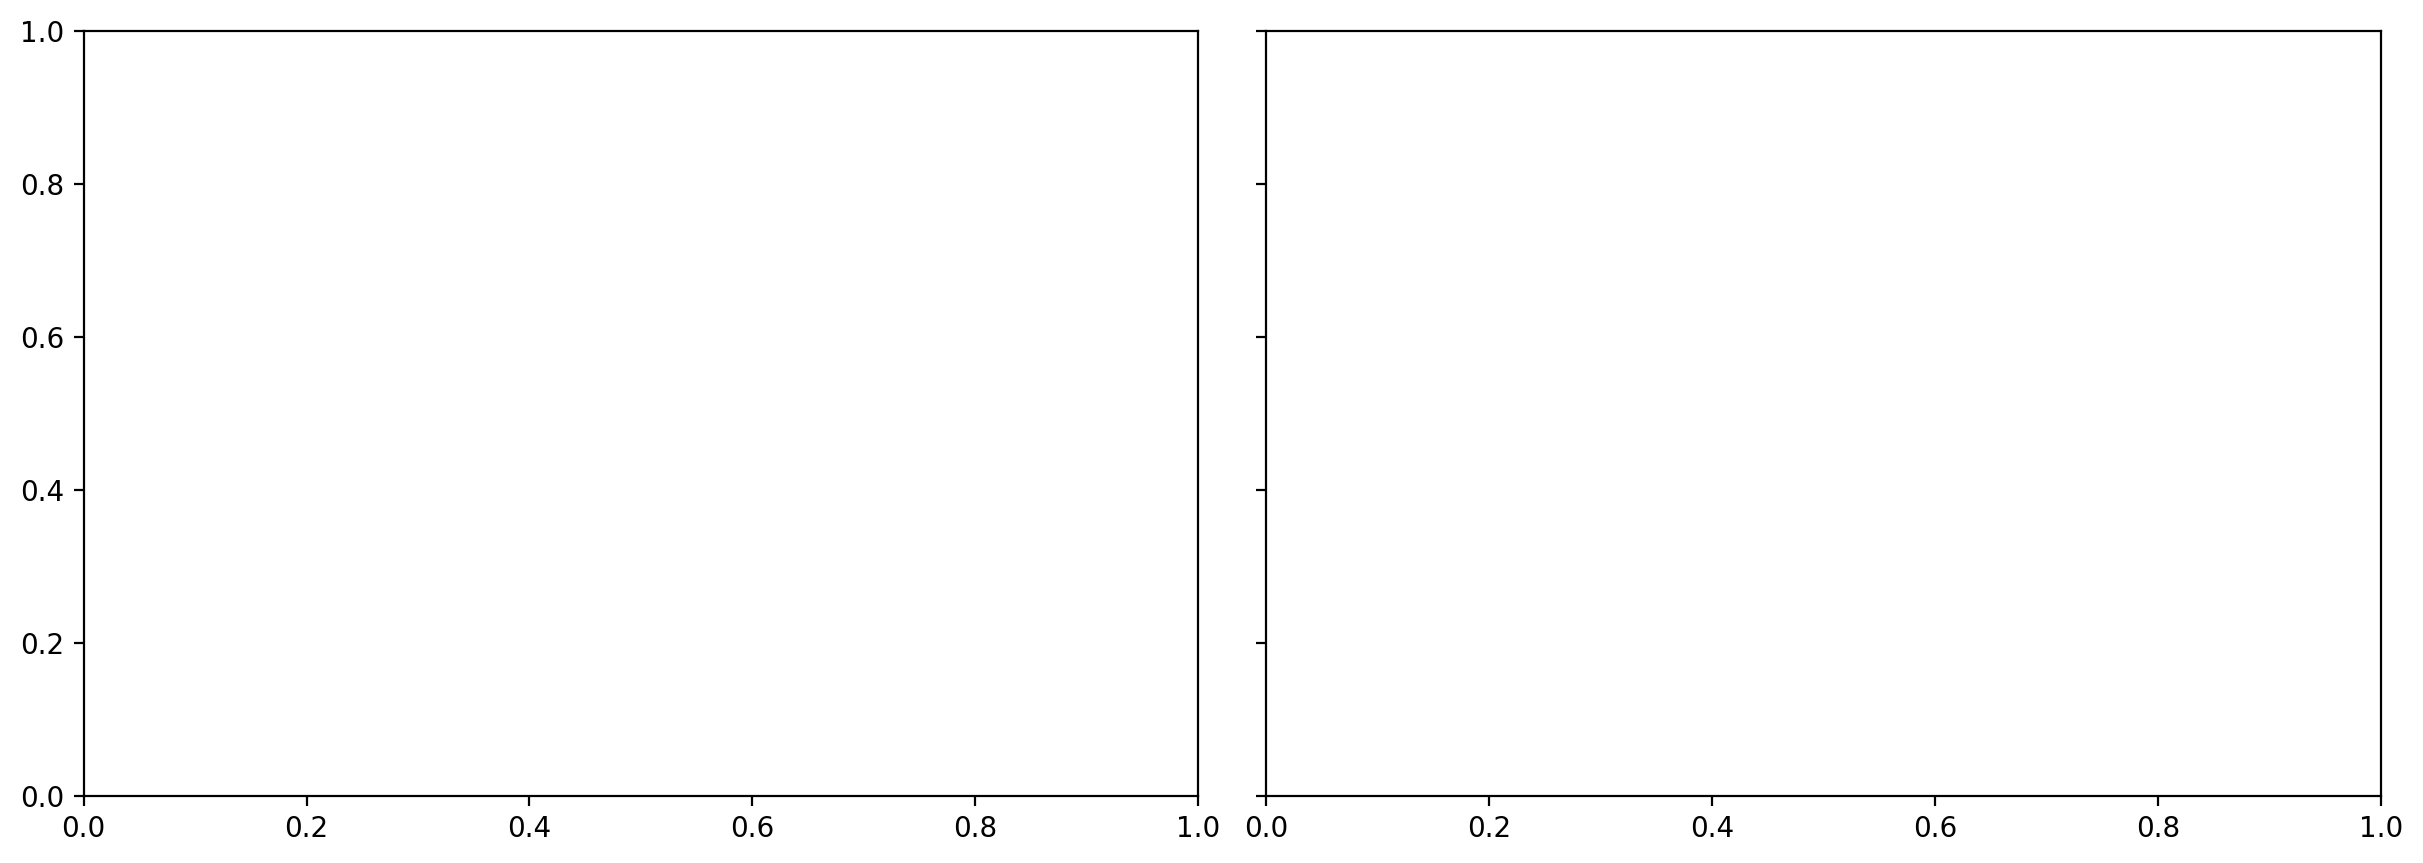

In [102]:
def monthly_jet_latitude(u, model, experiment):
    start, end = (1981, 2014) if experiment == "Historical" else (2035, 2069)
    u = u.sel(time=slice(str(start), str(end))).sortby("time")

    expected = [100*y + m for y in range(start, end + 1) for m in range(1, 13)]
    actual = u.time.dt.year * 100 + u.time.dt.month
    if not np.array_equal(actual.values, expected):
        raise ValueError(f"{model} {experiment}: expected all 12 months in each year.")

    u = u.assign_coords(lon=((u.lon + 180) % 360) - 180)
    u = u.sortby("lon").sortby("lat").sel(lon=slice(-25, 25), lat=slice(0, 25))

    if experiment == "Historical":
        u600 = u.interp(plev=60000)  # CMIP6 plev in Pa
    elif model == "UKESM":
        p_hpa = height_to_pressure(u.lev.values) / 100
        u = u.assign_coords(lev=p_hpa).isel(lev=np.isfinite(p_hpa)).sortby("lev")
        u600 = u.interp(lev=600)
    else:
        u600 = u.sortby("lev").interp(lev=600)  # WACCM nominal hPa

    # Locate the minimum after forming the monthly climatological wind profile.
    profile = u600.mean("lon").groupby("time.month").mean("time").compute()
    jet_lat = profile.idxmin("lat", skipna=True)
    jet_u = profile.min("lat", skipna=True)

    interior = (jet_lat > profile.lat.min()) & (jet_lat < profile.lat.max())
    return jet_lat.where((jet_u < 0) & interior)


jet_lat = {
    key: monthly_jet_latitude(u, *key)
    for key, u in winds.items()
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True, layout="constrained")
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul",
          "Aug", "Sep", "Oct", "Nov", "Dec", "Jan"]

for ax, model, letter in zip(axes, ["UKESM", "WACCM"], ["a", "b"]):
    for experiment, color in [("Historical", "0.3"), ("HiLLA", "tab:blue")]:
        lat = jet_lat[model, experiment].sel(month=range(1, 13)).values
        ax.plot(range(1, 14), np.r_[lat, lat[0]], marker="o", ms=4,
                lw=2, color=color, label=experiment)

    ax.set_title(f"({letter}) {model}", loc="left")
    ax.set_xticks(range(1, 14), labels)
    ax.set_xlim(1, 13)
    ax.set_ylim(0, 25)
    ax.set_xlabel("Month")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Latitude of 600-hPa easterly maximum (°N)")
axes[1].legend(frameon=False)
plt.show()

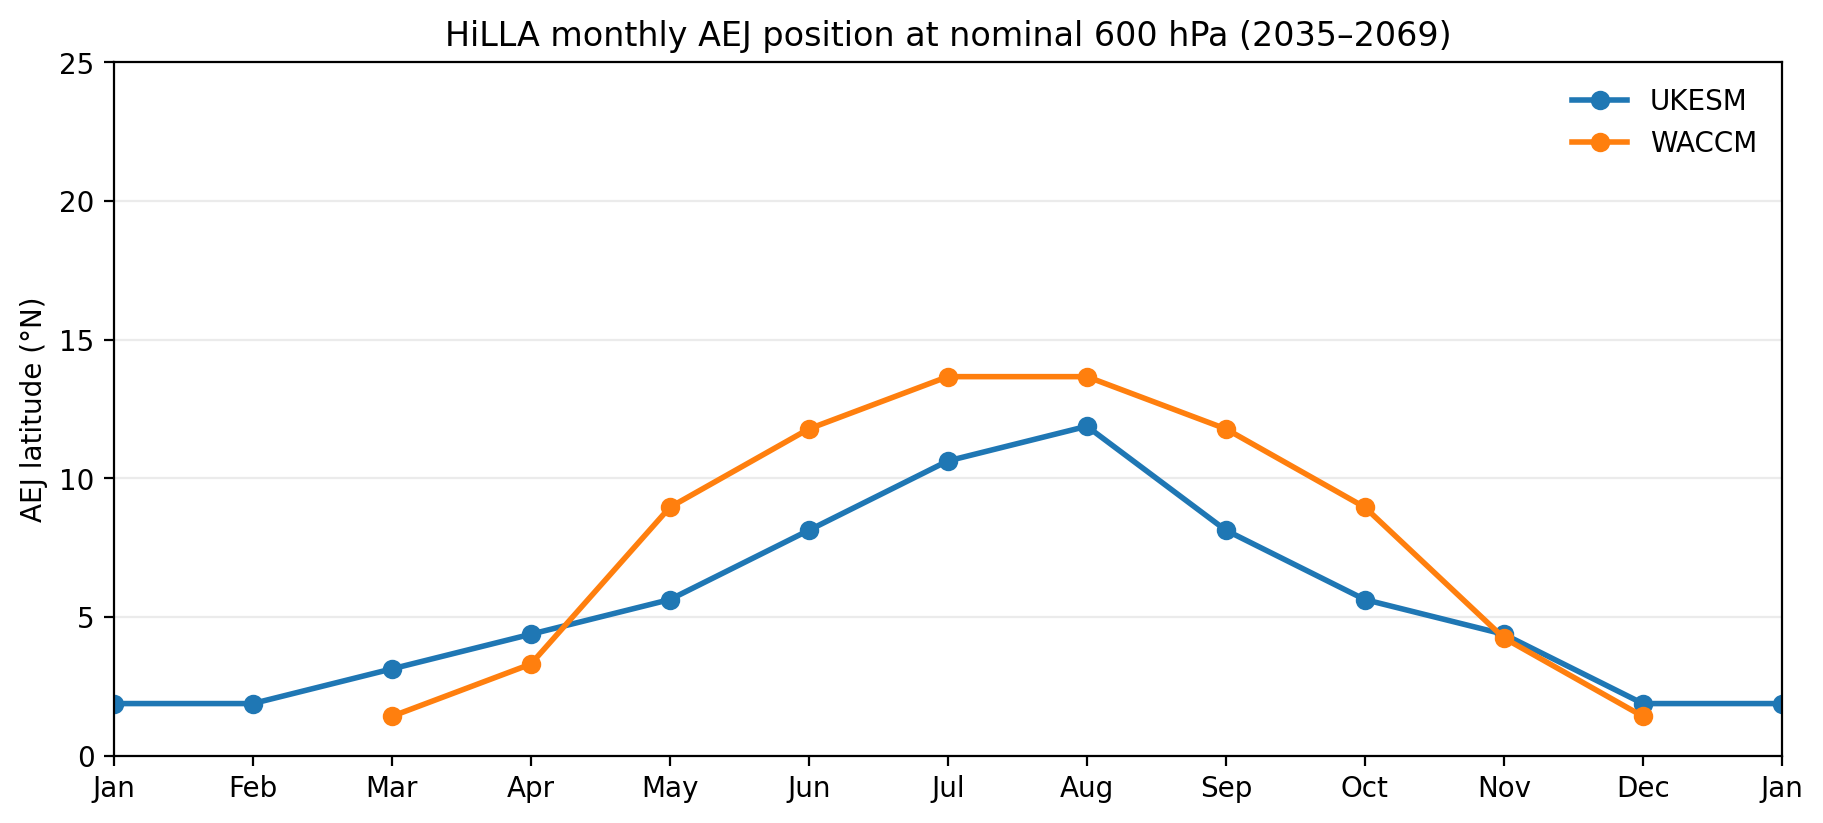

In [103]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
jet_lat = {}

for (model, experiment), u in winds.items():
    lat = monthly_jet_latitude(u, model, experiment).sel(month=range(1, 13))
    jet_lat[model] = lat

    # Repeat January only to close the plotted seasonal cycle.
    ax.plot(range(1, 14), np.r_[lat.values, lat.values[0]],
            marker="o", linewidth=2, label=model)

ax.set_xticks(range(1, 14), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec", "Jan",
])
ax.set_xlim(1, 13)
ax.set_ylim(0, 25)
ax.set_ylabel("AEJ latitude (°N)")
ax.set_title("HiLLA monthly AEJ position at nominal 600 hPa (2035–2069)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()